In [1]:
import pandas as pd
test = pd.read_csv("ramen-ratings.csv")
test.head()

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN


In [2]:
train = pd.read_csv("ramen-ratings.csv")
train.head()

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN


In [3]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2580 entries, 0 to 2579
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Review #  2580 non-null   int64
 1   Brand     2580 non-null   str  
 2   Variety   2580 non-null   str  
 3   Style     2578 non-null   str  
 4   Country   2580 non-null   str  
 5   Stars     2580 non-null   str  
 6   Top Ten   41 non-null     str  
dtypes: int64(1), str(6)
memory usage: 141.2 KB


In [4]:
 # Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
count,2580.000000,2580,2580,2578,2580,2580,41
unique,NaN,355,2413,7,38,51,38
top,NaN,Nissin,Beef,Pack,Japan,4,\n
freq,NaN,381,7,1531,352,384,4
mean,1290.500000,NaN,NaN,NaN,NaN,NaN,NaN
std,744.926171,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,645.750000,NaN,NaN,NaN,NaN,NaN,NaN
50%,1290.500000,NaN,NaN,NaN,NaN,NaN,NaN
75%,1935.250000,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Style         2
Top Ten    2539
dtype: int64

In [6]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [7]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [8]:
 # Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object', 'string']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [9]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [10]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [11]:
# Stars diubah ke angka lebih dulu; nilai "Unrated" menjadi NaN lalu barisnya dibuang
df['Stars'] = pd.to_numeric(df['Stars'], errors='coerce')
df = df.dropna(subset=['Stars'])
df['Stars'].dtype

dtype('float64')

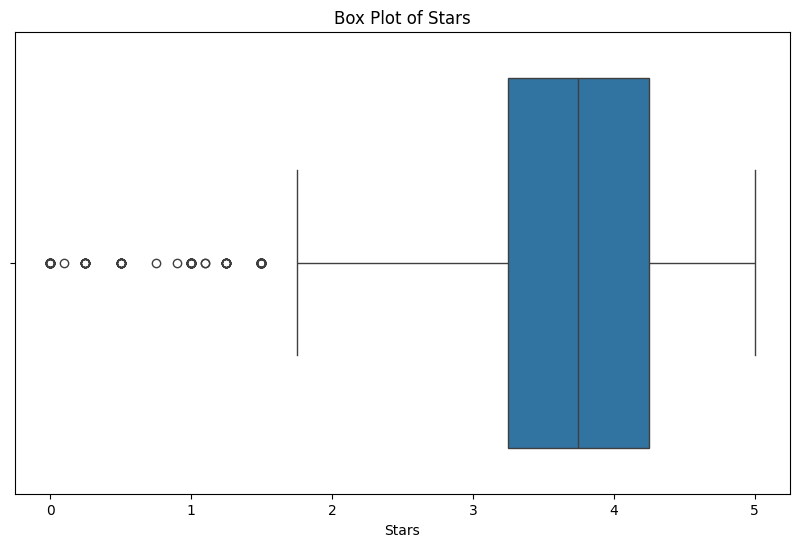

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# boxplot untuk Stars (sebelumnya hanya Review #, yang cuma nomor urut)
for feature in ['Stars']:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [13]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df['Stars'].quantile(0.25)
Q3 = df['Stars'].quantile(0.75)
IQR = Q3 - Q1

In [14]:
# Mengganti outlier dengan nilai batas terdekat
# cell penggantian median dihapus karena membuat cell ini tidak berefek
df['Stars'] = df['Stars'].apply(lambda x: (Q1 - 1.5 * IQR) if x < (Q1 - 1.5 * IQR) else (Q3 + 1.5 * IQR) if x > (Q3 + 1.5 * IQR) else x)

In [15]:
from sklearn.preprocessing import StandardScaler

# standarisasi fitur nimerik
# hanya Review # yang distandarisasi; Stars (target) sengaja tidak, supaya tetap rating asli
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

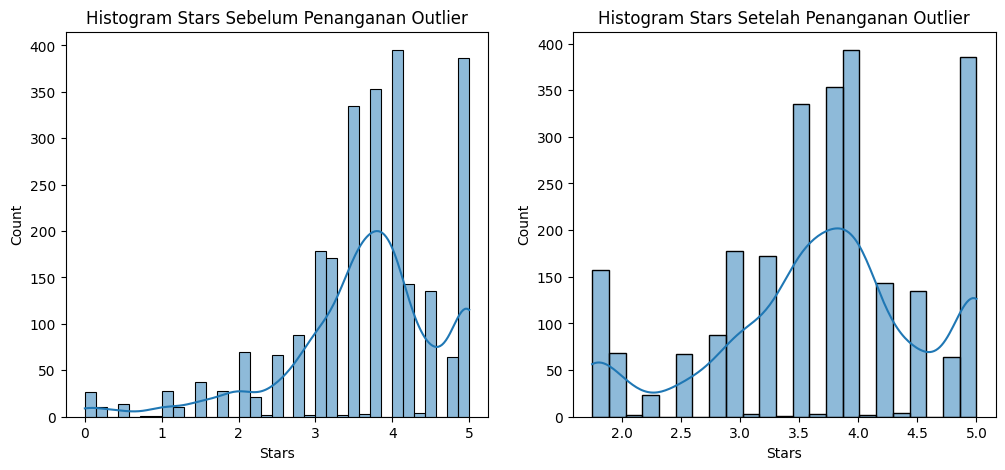

In [16]:
# dua histogram digabung dalam satu cell, dan judulnya sesuai isi
# (Stars tidak distandarisasi; yang dibandingkan adalah sebelum dan sesudah penanganan outlier)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(pd.to_numeric(train['Stars'], errors='coerce'), kde=True)
plt.title("Histogram Stars Sebelum Penanganan Outlier")

plt.subplot(1, 2, 2)
sns.histplot(df['Stars'], kde=True)
plt.title("Histogram Stars Setelah Penanganan Outlier")
plt.show()

In [17]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Review #, Brand, Variety, Style, Country, Stars]
Index: []


In [18]:
# Menghapus baris duplikat
# drop_duplicates harus dipanggil dengan tanda kurung ()
df = df.drop_duplicates().reset_index(drop=True)

print("Dataframe setelah menghapus duplikat:")
print(df)

Dataframe setelah menghapus duplikat:
      Review #           Brand  \
0     1.733629       New Touch   
1     1.732286        Just Way   
2     1.730943          Nissin   
3     1.729599         Wei Lih   
4     1.728256  Ching's Secret   
...        ...             ...   
2572 -1.725419           Vifon   
2573 -1.726762         Wai Wai   
2574 -1.728105         Wai Wai   
2575 -1.729449         Wai Wai   
2576 -1.730792        Westbrae   

                                                Variety Style   Country  Stars  
0                             T's Restaurant Tantanmen    Cup     Japan   3.75  
1     Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...  Pack    Taiwan   1.75  
2                         Cup Noodles Chicken Vegetable   Cup       USA   2.25  
3                         GGE Ramen Snack Tomato Flavor  Pack    Taiwan   2.75  
4                                       Singapore Curry  Pack     India   3.75  
...                                                 ...   ...      

In [19]:
# baris pd.read_csv dihapus, karena membaca ulang data mentah dan menghilangkan semua pembersihan di atas
category_features = df.select_dtypes(include=['object', 'string']).columns
df[category_features]

,Brand,Variety,Style,Country
0,New Touch,T's Restaurant Tantanmen,Cup,Japan
1,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan
2,Nissin,Cup Noodles Chicken Vegetable,Cup,USA
3,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan
4,Ching's Secret,Singapore Curry,Pack,India
...,...,...,...,...
2572,Vifon,"Hu Tiu Nam Vang [""Phnom Penh"" style] Asian Sty...",Bowl,Vietnam
2573,Wai Wai,Oriental Style Instant Noodles,Pack,Thailand
2574,Wai Wai,Tom Yum Shrimp,Pack,Thailand
2575,Wai Wai,Tom Yum Chili Flavor,Pack,Thailand


In [20]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Review #,Stars,Brand_1 To 3 Noodles,Brand_7 Select,Brand_7 Select/Nissin,Brand_A-One,Brand_A-Sha Dry Noodle,Brand_A1,Brand_ABC,Brand_Acecook,...,Country_Sarawak,Country_Singapore,Country_South Korea,Country_Sweden,Country_Taiwan,Country_Thailand,Country_UK,Country_USA,Country_United States,Country_Vietnam
0,1.733629,3.75,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1.732286,1.75,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
2,1.730943,2.25,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,1.729599,2.75,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,1.728256,3.75,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2572,-1.725419,3.50,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
2573,-1.726762,1.75,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2574,-1.728105,2.00,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2575,-1.729449,2.00,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False


In [21]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
# pakai .copy() supaya df tidak ikut berubah
df_lencoder = df.copy()

# Stars sudah berupa angka, jadi tidak ikut di-encode (category_features hanya kolom teks)
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# menampilkan hasil
df_lencoder

,Review #,Brand,Variety,Style,Country,Stars
0,1.733629,190,2186,4,18,3.75
1,1.732286,119,1443,5,32,1.75
2,1.730943,192,454,4,35,2.25
3,1.729599,336,709,5,32,2.75
4,1.728256,38,1951,5,16,3.75
...,...,...,...,...,...,...
2572,-1.725419,329,850,1,37,3.50
2573,-1.726762,332,1511,5,33,1.75
2574,-1.728105,332,2249,5,33,2.00
2575,-1.729449,332,2245,5,33,2.00


In [22]:
df_lencoder.head()

,Review #,Brand,Variety,Style,Country,Stars
0,1.733629,190,2186,4,18,3.75
1,1.732286,119,1443,5,32,1.75
2,1.730943,192,454,4,35,2.25
3,1.729599,336,709,5,32,2.75
4,1.728256,38,1951,5,16,3.75


In [23]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'missing values': missing_values,
    'percentage': missing_percentage
}).sort_values(by='missing values', ascending=False)

missing_data[missing_data['missing values'] > 0] # Menampilkan kolom dengan missing values

,missing values,percentage


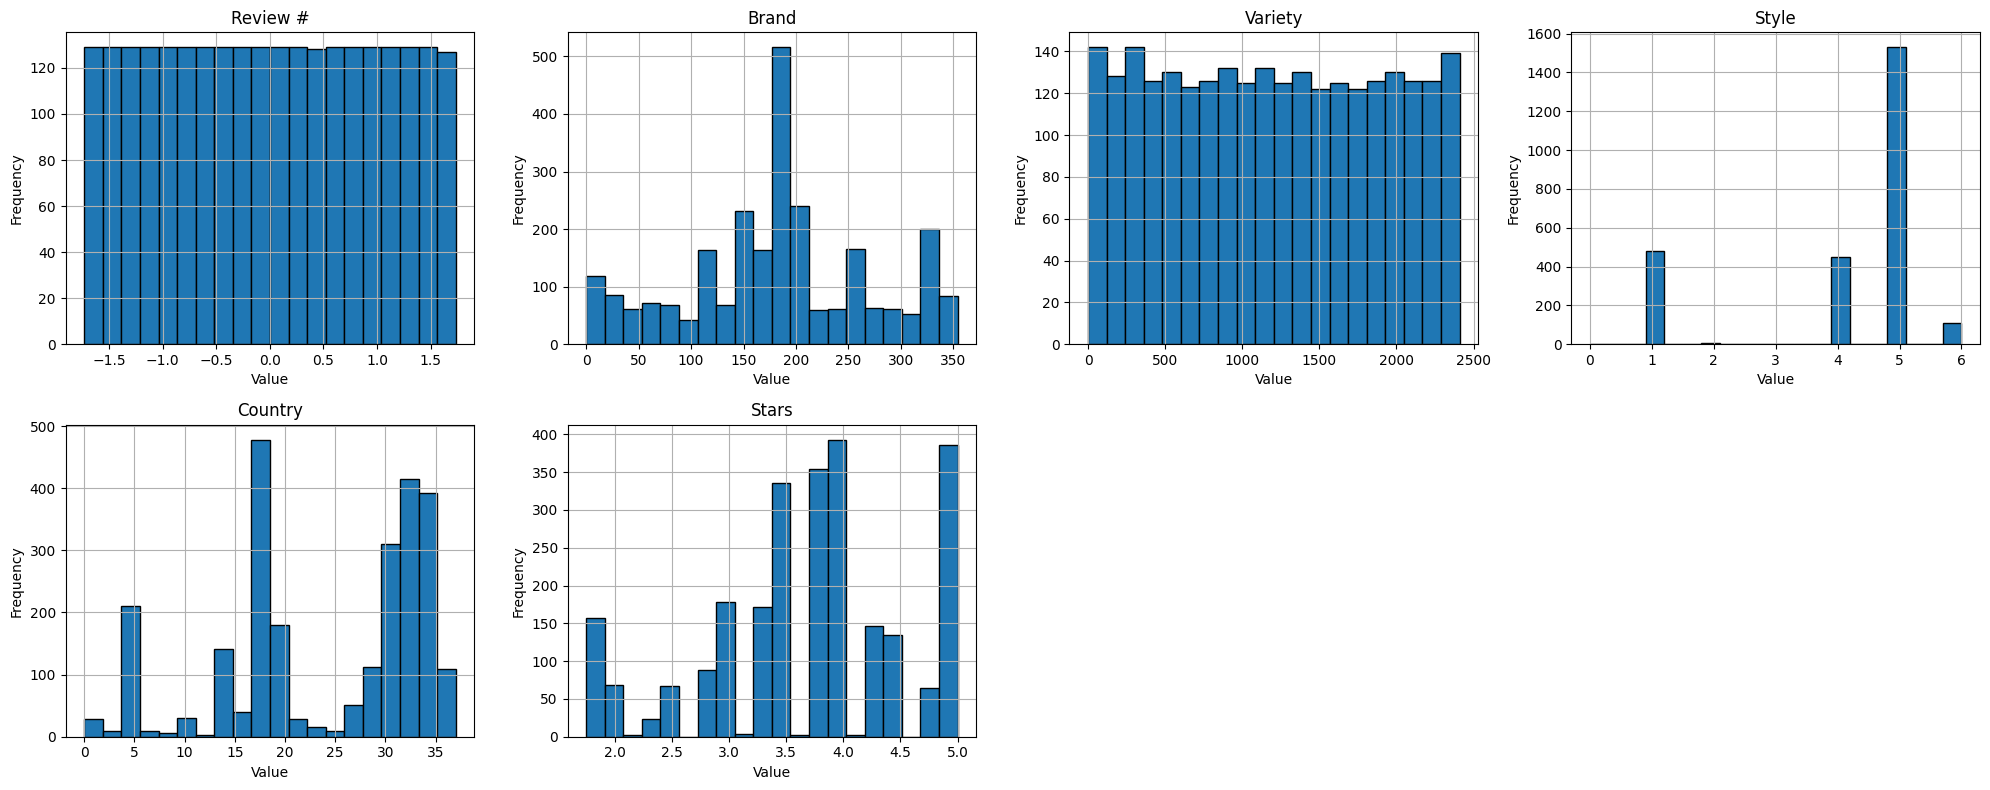

In [24]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

 # Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

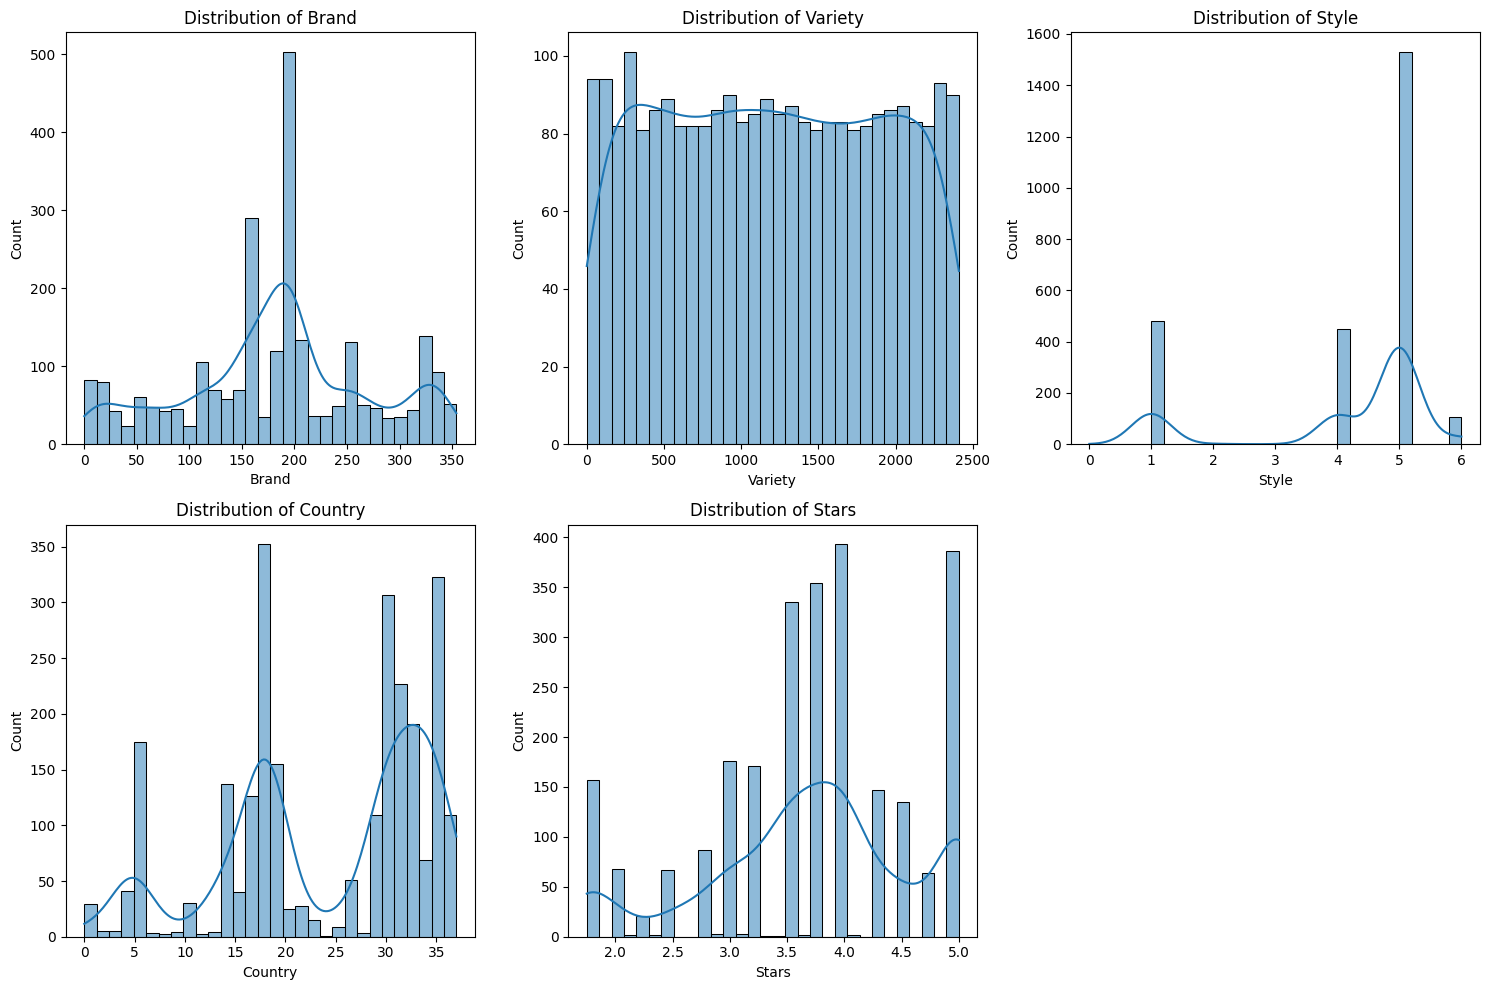

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['Brand', 'Variety', 'Style', 'Country', 'Stars']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()


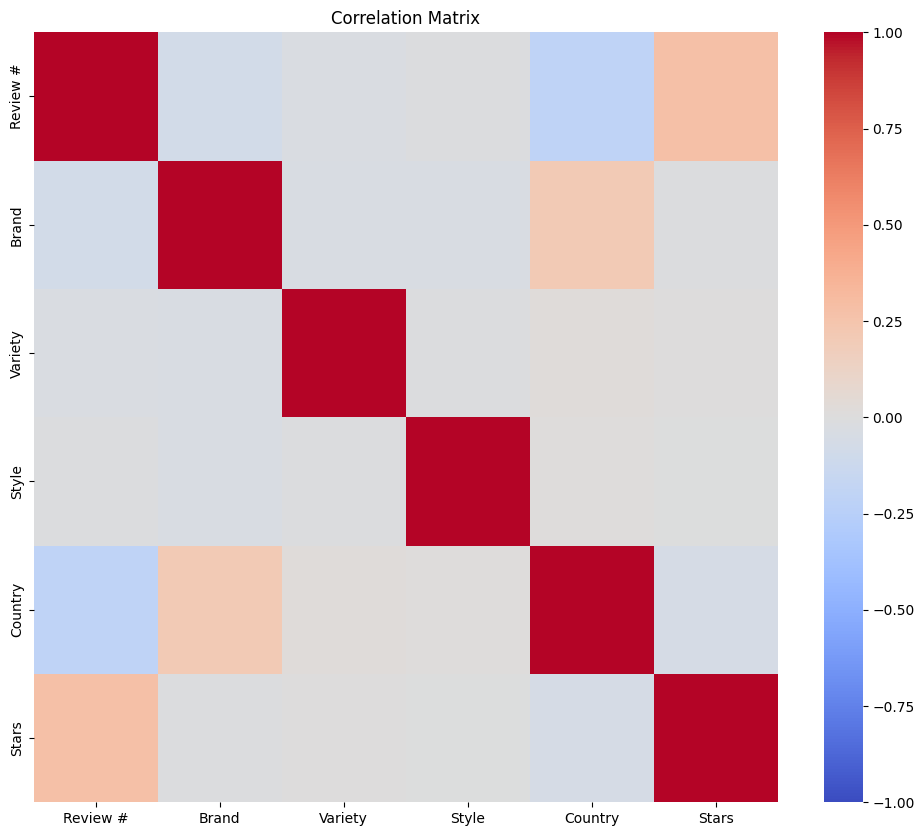

In [26]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

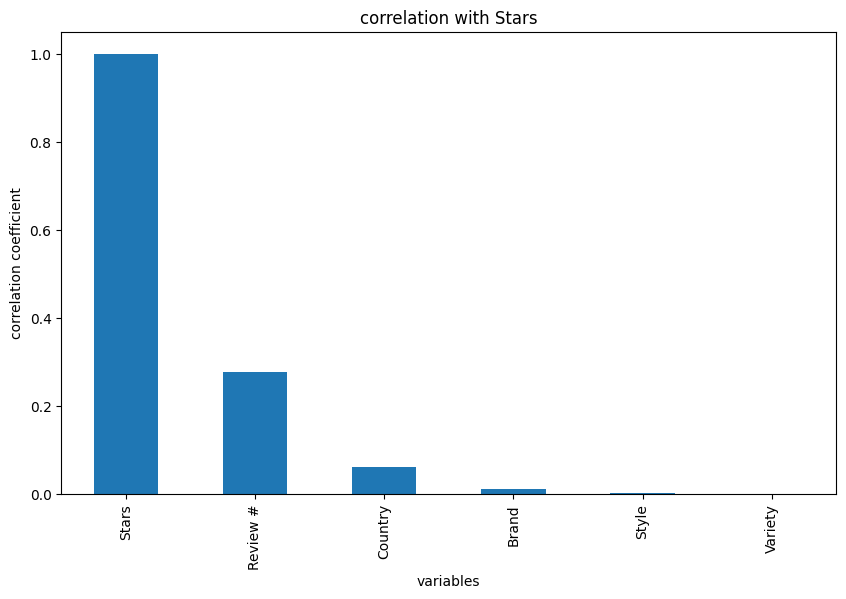

In [27]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['Stars']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'correlation with Stars')
plt.xlabel('variables')
plt.ylabel('correlation coefficient')
plt.show()

In [28]:
import sklearn

In [29]:
# Memisahkan fitur (X) dan target (y)
# Review # dibuang karena hanya nomor urut, bukan ciri mi
X = df_lencoder.drop(columns=['Stars', 'Review #'])
y = df_lencoder['Stars']

In [30]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [31]:
# menghitung panjang/jumlah data
print("jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("jumlah data test: ",len(x_test))

jumlah data:  2577
jumlah data latih:  2061
jumlah data test:  516


In [32]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=3).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasir
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.736384,0.870925,-0.0009


In [34]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.736384,0.870925,-0.000900
Linear Regression,0.736392,0.870928,-0.000903


In [35]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.736384,0.870925,-0.000900
Linear Regression,0.736392,0.870928,-0.000903
GradientBoostingRegressor,0.669068,0.725424,0.166315


In [36]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [38]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)
